### ERCOT weather-zone validation — all 8 zones

Rewritten. The previous version validated **zone 3B only**, against a county -> ERCOT-weather-zone
crosswalk read by eye off ERCOT's PNG map (`Weather.jpg`), and explicitly gave up on the other
four IECC zones because their ERCOT-zone boundaries were too fuzzy to read visually.

`texas7k_bus_with_climate_zone.csv` removes that obstacle: it carries an **`Area_Name`** column
per bus, holding exactly ERCOT's 8 weather-zone names (Coast, East, Far West, North, North
Central, South, South Central, West). The crosswalk is therefore now **per bus, from the grid
model itself** — no county approximation, no visual map reading — and validation extends to all
8 ERCOT zones instead of one.

The reconstruction is aggregated by ERCOT zone *across* IECC zones: an ERCOT zone such as SCENT
draws buses from IECC 2A and 3A at once, which the old county-based approach could not express.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

exports = Path("../../loadcurves/exports")
statewide_dir = Path("..")
exports_out_dir = statewide_dir / "exports"
metrics_dir = statewide_dir / "metrics"

bus_master = pd.read_csv(statewide_dir / "bus_zone_master.csv", dtype={"COUNTYFP": str})
bus_master["Bus_Number"] = bus_master["Bus_Number"].astype(str)

# Area_Name -> the column names ERCOT uses in Native_Load_2018.xlsx
AREA_TO_ERCOT = {
    "Coast": "COAST", "East": "EAST", "Far West": "FWEST", "North": "NORTH",
    "North Central": "NCENT", "South": "SOUTH", "South Central": "SCENT", "West": "WEST",
}
bus_master["ercot_zone"] = bus_master["Area_Name"].map(AREA_TO_ERCOT)
assert bus_master["ercot_zone"].notna().all(), bus_master.loc[bus_master["ercot_zone"].isna(), "Area_Name"].unique()

print(pd.crosstab(bus_master["ercot_zone"], bus_master["iecc_zone"], margins=True))


iecc_zone     2A   2B    3A   3B   4B   All
ercot_zone                                 
COAST       1544    0     0    0    0  1544
EAST         265    0   231    0    0   496
FWEST          0    3     0  271    3   277
NCENT        274    0  1562   12    0  1848
NORTH          0    0   216   74  121   411
SCENT       1012   49    75    2    0  1138
SOUTH        483  147     0    0    0   630
WEST           2   47    58  266    0   373
All         3580  246  2142  625  124  6717


#### 1. Does `Area_Name` really mean ERCOT's weather zone?

Before trusting it, check it against something independent. The Texas 7k case is a peak-load
snapshot, so summing each area's `Load_MW` should land near that ERCOT zone's 2018 peak. It does
for six of the eight zones, and clearly does not for NORTH and EAST — stated as a caveat rather
than smoothed over.

In [2]:
ercot_raw = pd.read_excel(exports / "Native_Load_2018.xlsx", sheet_name="Native Load Report")

case_mw = bus_master.groupby("ercot_zone")["Load_MW"].sum()
ercot_peak = ercot_raw[list(AREA_TO_ERCOT.values())].max()

check = pd.DataFrame({
    "buses": bus_master.groupby("ercot_zone").size(),
    "case_peak_MW": case_mw,
    "ercot_2018_peak_MW": ercot_peak,
})
check["case / ERCOT"] = check["case_peak_MW"] / check["ercot_2018_peak_MW"]
print(check.round(2).sort_values("case / ERCOT"))
ercot_coincident = ercot_raw[list(AREA_TO_ERCOT.values())].sum(axis=1).max()
print(f"\nStatewide: case {case_mw.sum():,.0f} MW vs ERCOT coincident peak "
      f"{ercot_coincident:,.0f} MW ({case_mw.sum() / ercot_coincident:.2f}x)")

TRUSTED = [z for z in check.index if 0.80 <= check.loc[z, "case / ERCOT"] <= 1.20]
print(f"\nZones where the case peak matches ERCOT's within +/-20%: {TRUSTED}")
print(f"Zones flagged as a boundary mismatch (validated but reported separately): "
      f"{[z for z in check.index if z not in TRUSTED]}")


       buses  case_peak_MW  ercot_2018_peak_MW  case / ERCOT
SCENT   1138      11899.68            14166.70          0.84
SOUTH    630       5646.12             6176.11          0.91
WEST     373       1886.33             2083.58          0.91
NCENT   1848      24706.50            26499.24          0.93
FWEST    277       3558.88             3655.01          0.97
COAST   1544      20130.69            20269.85          0.99
EAST     496       3473.65             2620.84          1.33
NORTH    411       3364.74             1521.85          2.21

Statewide: case 74,667 MW vs ERCOT coincident peak 73,308 MW (1.02x)

Zones where the case peak matches ERCOT's within +/-20%: ['COAST', 'FWEST', 'NCENT', 'SCENT', 'SOUTH', 'WEST']
Zones flagged as a boundary mismatch (validated but reported separately): ['EAST', 'NORTH']


#### 2. Aggregate the bus-level reconstruction by ERCOT zone

All five IECC zones' residential and commercial exports are concatenated into one statewide
bus x hour table, then grouped by the bus's `ercot_zone`.

In [3]:
res_parts, com_parts = [], []
for z in ["2A", "2B", "3A", "3B", "4B"]:
    r = pd.read_csv(exports_out_dir / f"residential_bus_load_profiles_8760_{z}.csv", index_col=0, parse_dates=True)
    r.columns = r.columns.astype(str)
    res_parts.append(r)
    cpath = exports_out_dir / f"commercial_bus_load_profiles_8760_{z}.csv"
    if cpath.exists():
        c = pd.read_csv(cpath, index_col=0, parse_dates=True)
        c.columns = c.columns.astype(str)
        com_parts.append(c)

res = pd.concat(res_parts, axis=1).fillna(0.0)
com = pd.concat(com_parts, axis=1).fillna(0.0)
res = res.T.groupby(level=0).sum().T if res.columns.duplicated().any() else res
com = com.T.groupby(level=0).sum().T if com.columns.duplicated().any() else com

total = res.add(com, fill_value=0.0)
print(f"Statewide reconstruction: {total.shape[0]} hours x {total.shape[1]} buses "
      f"(residential {res.shape[1]}, commercial {com.shape[1]})")

bus_ercot = bus_master.set_index("Bus_Number")["ercot_zone"]
matched = total.columns.intersection(bus_ercot.index)
print(f"Buses matched to an ERCOT zone: {len(matched)} / {total.shape[1]}")

recon_mw = (total[matched].T.groupby(bus_ercot.loc[matched]).sum().T) / 1000  # kWh -> MW
recon_mw["ERCOT"] = recon_mw.sum(axis=1)
print(recon_mw.max().round(0))


Statewide reconstruction: 8760 hours x 6717 buses (residential 6717, commercial 6717)
Buses matched to an ERCOT zone: 6717 / 6717


ercot_zone
COAST    13234.0
EAST      3494.0
FWEST     2300.0
NCENT    17000.0
NORTH     1731.0
SCENT     9039.0
SOUTH     3994.0
WEST       915.0
ERCOT    49198.0
dtype: float64


#### 3. Compare against ERCOT actual, zone by zone

Same DST-aware parsing as the Coast validation (ERCOT is Central *with* DST and "24:00" hour
endings; the reconstruction is on NREL's fixed EST, i.e. `Etc/GMT+5`).

In [4]:
ercot = ercot_raw.copy()
ercot["HourEnding"] = ercot["HourEnding"].astype(str)
is_dst = ercot["HourEnding"].str.contains(" DST", regex=False)
ercot["HourEnding"] = ercot["HourEnding"].str.replace(" DST", "", regex=False)
mask24 = ercot["HourEnding"].str.contains("24:00")
ercot["HourEnding"] = ercot["HourEnding"].str.replace("24:00", "00:00")
ts = pd.to_datetime(ercot["HourEnding"])
ts.loc[mask24] += pd.Timedelta(days=1)
ercot["date_time"] = ts.dt.tz_localize("US/Central", ambiguous=is_dst, nonexistent="shift_forward")
ercot = ercot.set_index("date_time").tz_convert("Etc/GMT+5")
ercot.index = ercot.index.tz_localize(None)

common = recon_mw.index.intersection(ercot.index)
rows = []
for z in list(AREA_TO_ERCOT.values()) + ["ERCOT"]:
    y = ercot.loc[common, z]
    r = recon_mw.loc[common, z]
    rows.append({
        "ercot_zone": z,
        "boundary_check": "ok" if z in TRUSTED or z == "ERCOT" else "MISMATCH",
        "ercot_peak_MW": y.max(),
        "recon_peak_MW": r.max(),
        "peak_coverage": r.max() / y.max(),
        "pearson": y.corr(r),
        "mae_MW": (y - r).abs().mean(),
    })
summary = pd.DataFrame(rows).set_index("ercot_zone")
print(summary.round(3))
summary.to_csv(metrics_dir / "ercot_zone_validation_all.csv")


           boundary_check  ercot_peak_MW  recon_peak_MW  peak_coverage  \
ercot_zone                                                               
COAST                  ok      20269.849      13233.593          0.653   
EAST             MISMATCH       2620.839       3494.216          1.333   
FWEST                  ok       3655.014       2299.731          0.629   
NORTH            MISMATCH       1521.845       1730.565          1.137   
NCENT                  ok      26499.241      17000.033          0.642   
SOUTH                  ok       6176.106       3993.665          0.647   
SCENT                  ok      14166.702       9039.046          0.638   
WEST                   ok       2083.579        914.537          0.439   
ERCOT                  ok      73308.153      49197.648          0.671   

            pearson     mae_MW  
ercot_zone                      
COAST         0.900   5915.384  
EAST          0.911    219.436  
FWEST         0.629   1821.389  
NORTH         0.905 

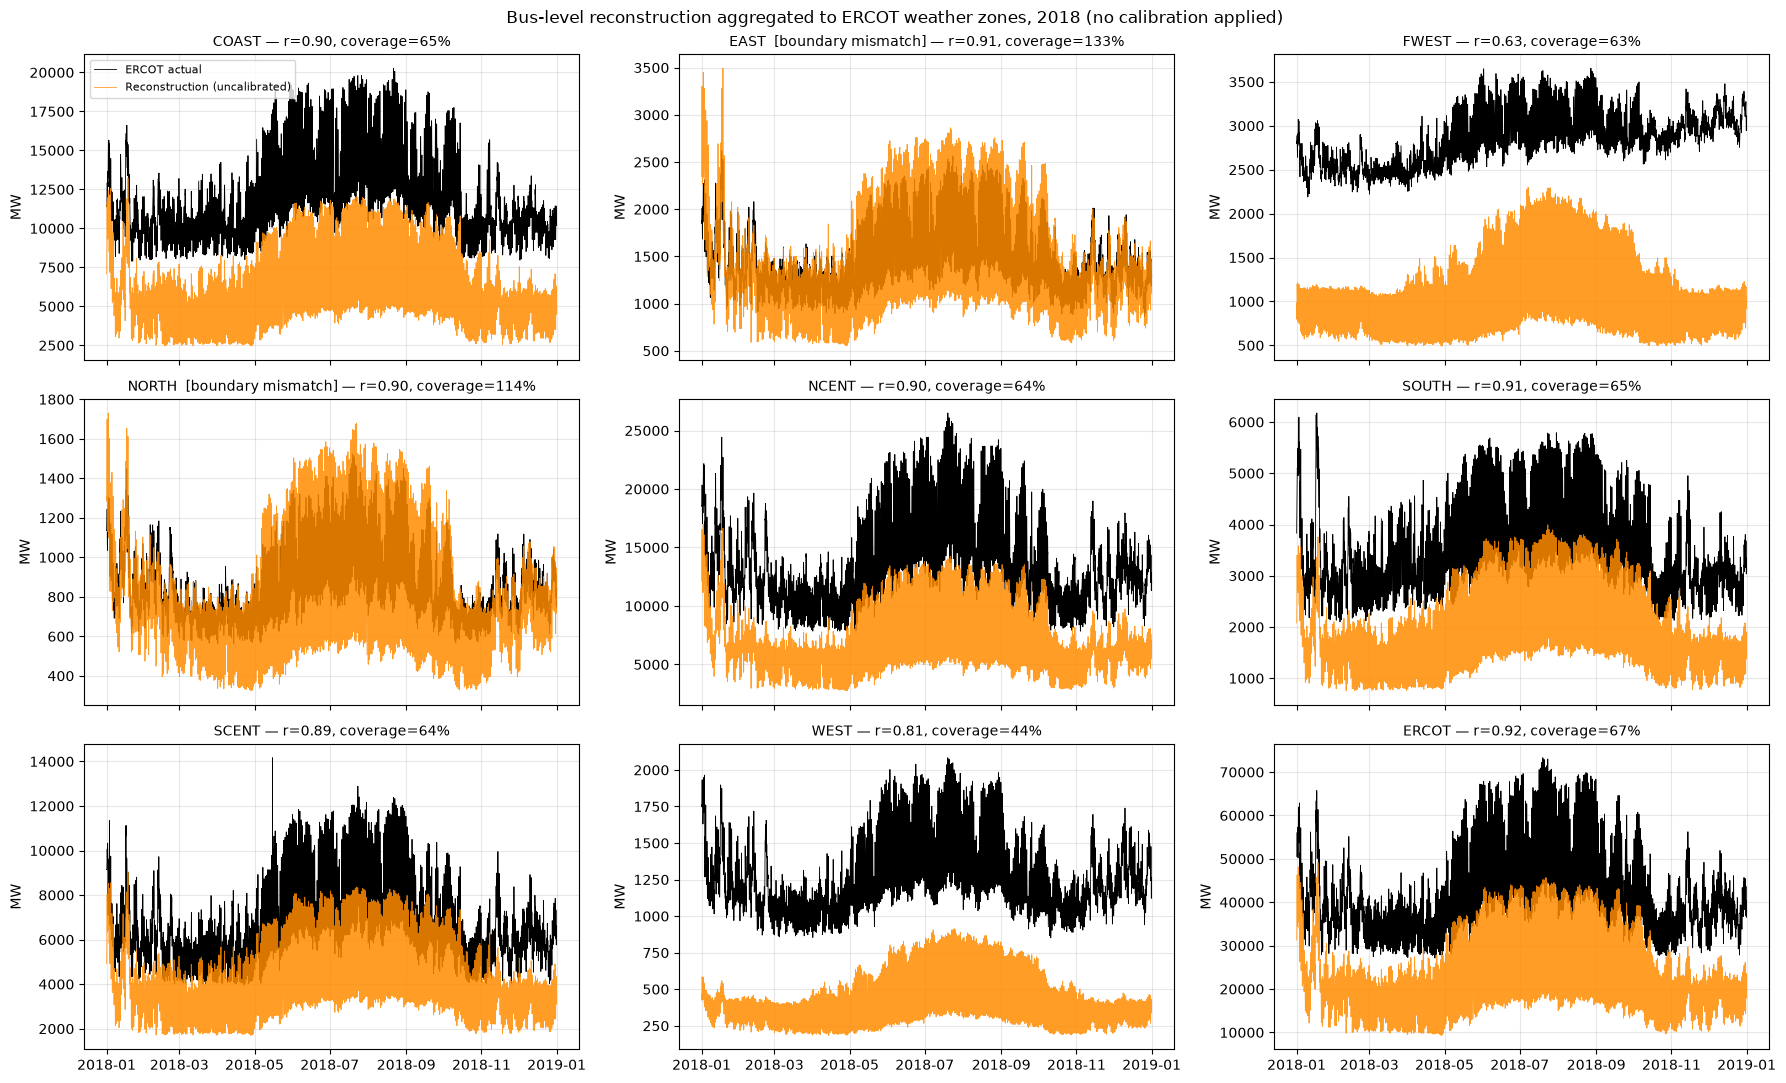

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(18, 11), sharex=True)
for ax, z in zip(axes.ravel(), list(AREA_TO_ERCOT.values()) + ["ERCOT"]):
    y = ercot.loc[common, z]
    r = recon_mw.loc[common, z]
    ax.plot(y.index, y, color="black", linewidth=0.6, label="ERCOT actual")
    ax.plot(r.index, r, color="darkorange", linewidth=0.6, alpha=0.85, label="Reconstruction (uncalibrated)")
    flag = "" if (z in TRUSTED or z == "ERCOT") else "  [boundary mismatch]"
    ax.set_title(f"{z}{flag} — r={y.corr(r):.2f}, coverage={r.max()/y.max():.0%}", fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_ylabel("MW")
axes.ravel()[0].legend(fontsize=8)
fig.suptitle("Bus-level reconstruction aggregated to ERCOT weather zones, 2018 (no calibration applied)")
plt.tight_layout()
plt.show()


#### Summary

Validation now covers **all 8 ERCOT weather zones plus the ERCOT total**, not just 3B, because the
bus -> ERCOT-zone assignment comes from the grid model's own `Area_Name` field instead of a
county crosswalk read off a picture.

Two caveats to keep in the paper:

- **NORTH and EAST**: the case's area load is 2.2x and 1.3x their ERCOT peak, so the synthetic
  case's NORTH/EAST boundaries do not coincide with ERCOT's for those two zones. Their rows are
  reported but flagged `MISMATCH` — a shape correlation there is still informative, a magnitude
  comparison is not. The other six zones sit within +/-20%.
- The reconstruction remains **uncalibrated** (no `RES_SCALE`/`COM_SCALE`) and carries **no
  industrial model outside Coast**, so peak coverage below 100% is expected everywhere; the
  shortfall is largest where industrial share is largest (WEST/FWEST — the Permian result the
  previous version of this notebook already identified).